In [59]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [60]:
def f(x):
    return 3*x**2 + 2*x + 1
f(3.0)

34.0

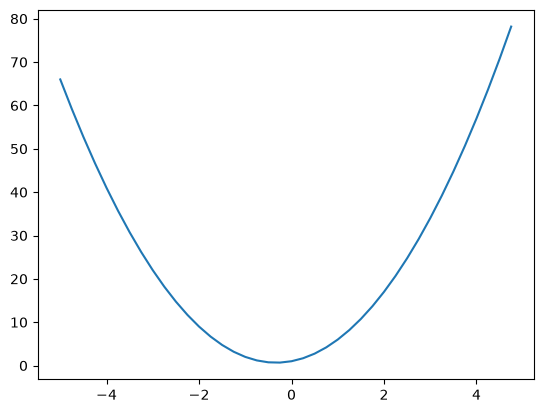

In [61]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [62]:
# h = 0.00001
# x = 3.0
# (f(x + h) - f(x)) / h

In [63]:
# a = 2.0
# b = -3.0
# c = 10.0
# d = a*b + c
# print(d)

In [64]:
# h = .0000001
# a = 2.0
# b = -3.0
# c = 10.0

# d1 = a*b + c
# a += h
# d2 = a*b + c

# print('d1', d1)
# print('d2', d2)
# print('slope', (d2 - d1) / h)

In [65]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    #print formatted expression
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __neg__(self): # -self
        return self * -1
    
    def __sub__(self, other): # self - other
        return self + (-other)
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')
    
        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
    
        return out

    def __rmul__(self, other):
        return self * other

    def __radd__(self, other):
        return self + other

    def __true__(self, other):
        return self * other**-1

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad 
        out._backward = _backward
        return out

    def backward(self):
        
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

# a = Value(2.0, label='a')
# b = Value(-3.0, label='b')
# c = Value(10.0, label='c')
# # copy the 2*3 + 10 expression above
# e = a*b; e.label = 'e'
# d = e + c; d.label = 'd'
# f = Value(-2.0, label = 'f')
# L = d*f; L.label = 'L'
# L
# #functionally (a.__mul__(b)).__add__(c)


In [66]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()

    # builds a set of all nodes and edges in a graph
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges
    
def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        
        #for any value in the graph , create rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it   
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot


In [67]:
# draw_dot(L)

In [68]:
# a.data += 0.01 * a.grad
# b.data += 0.01 * b.grad
# c.data += 0.01 * c.grad
# f.data += 0.01 * f.grad

# # copy the 2*3 + 10 expression above
# e = a * b
# d = e + c
# L = d * f

# print(L.data)

In [69]:
# L.grad = 1
# f.grad = 4.0
# d.grad = -2.0
# c.grad = -2.0
# e.grad = -2.0
# b.grad = -4.0
# a.grad = 6.0
# # # dd / dc = 1.0
# # # dL / dd = -2.0
# # # dL / dc = -2.0
# # # 

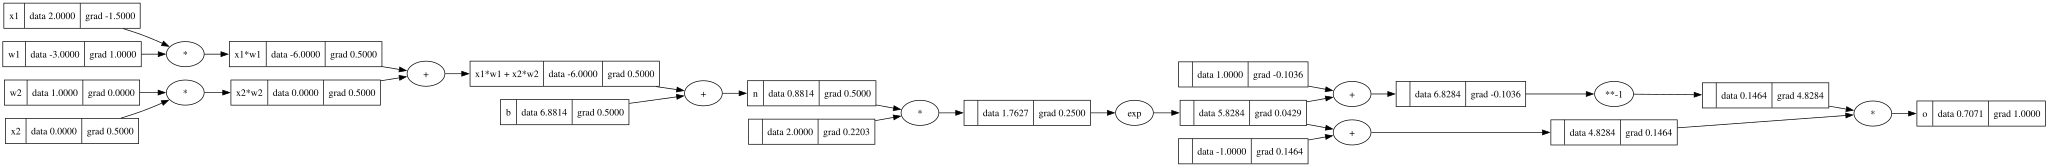

In [70]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# ---
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ---
o.label = 'o'
o.backward()
draw_dot(o)

In [71]:
# n.grad =  1 - o.data ** 2 
# b.grad = n.grad
# x1w1x2w2.grad = n.grad
# x2w2.grad = n.grad
# x1w1.grad = n.grad
# x1.grad = x1w1.grad * w1.data
# w1.grad = x1w1.grad * x1.data
# x2.grad = x2w2.grad * w2.data
# w2.grad = x2w2.grad * x2.data

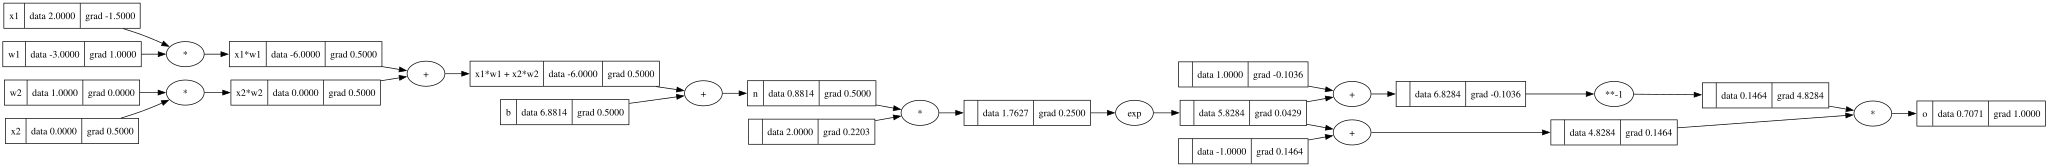

In [72]:
draw_dot(o)

In [73]:
o.backward()


In [74]:
import torch
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [75]:
import random



class Neuron:

  # init a random set of weights and biases from -1, 1 as the basis of the NN, these are all the "inputs" of an neuron
  def __init__(self, nin):
    # w is a [NX1] matrix associated with the connections for and arbitrary a_jk^(L) and a_jk^(L-1) such that ij in w is from j to k (r->l)
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    # bias associated with a layer
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    #build pre activation using zipper function, r val z
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    #apply activation 
    out = act.tanh()
    return out
  
  def parameters(self):
    return self.w + [self.b]

class Layer:
  
  def __init__(self, nin, nout):
    #create a set of neurons with nin input parameters and a size of nout neurons
    self.neurons = [Neuron(nin) for _ in range(nout)]

  
  def __call__(self, x):
    # calls Neuron with input x and gets a set of output neurons with activation functions applied
    outs = [n(x) for n in self.neurons]
    # 0 edge case
    return outs[0] if len(outs) == 1 else outs
  
  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  
  def __init__(self, nin, nouts):
    # sigma k - 1, n = 0 W^x from L - n + 1 to L
    # from the first layer each layer has an associated list of neurons as inputs, with each neuron having an associated list of weights and a column vector of biases
    # wraps nin(int) into a list and joins them
    sz = [nin] + nouts

    # builds each layer from the input to output, ie. forward prop.
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  # use inputs to get an output 
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x
  
  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


In [76]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4 , 4 , 1])
n(x)

Value(data=0.4921209970503707)

In [77]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [ ]:
# forward pass
for k in range(20):
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backwards pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # gradient descent/update
    for p in n.parameters():
        p.data += -0.01 * p.grad

    print(k, loss.data)


AttributeError: 'Value' object has no attribute 'parameters'

In [ ]:
# for p in n.parameters:
#     p.data += -0.01 * p.grad